# Customer Churn: Choosing the Best Survival Model

This notebook is a follow-up to [customer churn survival analysis.ipynb](customer%20churn%20survival%20analysis.ipynb). That notebook fit a Cox regression on four variables (`PaperlessBilling`, `SeniorCitizen`, `Dependents`, `gender`). Here we:

1. Fit a better model: a **Cox regression on all customer variables, stratified by contract type**.
2. Compare it against the existing notebook's model, and against a few alternatives, on customers the models haven't seen (5-fold cross-validation).
3. Explain why it's better, and what it tells us about churn.

Requires `lifelines` and `scikit-survival` (`pip install lifelines scikit-survival`), in addition to `pandas`, `matplotlib`, and `seaborn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style("whitegrid")
sns.set_palette("muted")

import lifelines
import sksurv
from lifelines import KaplanMeierFitter, CoxPHFitter, WeibullAFTFitter, LogLogisticAFTFitter, LogNormalAFTFitter
from lifelines.statistics import proportional_hazard_test
from sklearn.model_selection import StratifiedKFold
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored, integrated_brier_score
from sksurv.util import Surv

print("lifelines", lifelines.__version__, "| scikit-survival", sksurv.__version__, "| pandas", pd.__version__)

lifelines 0.30.3 | scikit-survival 0.28.0 | pandas 2.3.3


## Data

We use the same IBM telco churn dataset and the same cleaning steps as the existing notebook.

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
df.replace(r"^\s+", np.nan, inplace = True, regex = True)
df["TotalCharges"] = df.TotalCharges.astype(float)
df["Churn"] = (df.Churn == "Yes").astype(int)
df["SeniorCitizen"] = np.where(df.SeniorCitizen == 1, "Yes", "No")

# remove the 11 customers who just signed up (tenure of 0 months, none of them churned)
df = df[df.tenure != 0].reset_index(drop = True)
print(len(df), "customers,", df.Churn.sum(), "churned, longest tenure:", df.tenure.max(), "months")

7032 customers, 1869 churned, longest tenure: 72 months


### A note on how the data was collected

IBM describes `Churn` as customers who *left within the last month*. Taken literally, the dataset would only contain customers who were still subscribed a month ago, and we'd have to model it as left-truncated data. But that reading implies an implausible monthly churn rate (62% in the first month), and almost nobody would survive to 72 months, yet many customers in the data have. The dataset is fictional, so like the existing notebook we treat each customer as followed from sign-up until they churned or until today. The results should be read as an illustration of the method rather than facts about a real business.

In [3]:
by_tenure = df.groupby("tenure").Churn.agg(["size", "sum"])
implied_hazard = by_tenure["sum"] / by_tenure["size"]
print("Implied monthly churn rate at month 1 under the literal reading:", round(implied_hazard.loc[1], 2))
print("Implied probability of staying 72 months:", np.prod(1 - implied_hazard))

Implied monthly churn rate at month 1 under the literal reading: 0.62
Implied probability of staying 72 months: 4.605848120870525e-09


## Preparing the variables

- The add-on services (`OnlineSecurity`, `TechSupport`, ...) take the value "No internet service" exactly when `InternetService` is "No" (and similarly for `MultipleLines` and `PhoneService`). We fold those values into "No", since `InternetService` and `PhoneService` already capture them. Otherwise the dummy columns would be perfectly collinear.
- We leave out `MonthlyCharges` and `TotalCharges`. Monthly charges are almost completely determined by which services a customer has (see the R² below), so including them makes the service effects unstable. Total charges are roughly tenure × monthly charges, so they partly encode the outcome itself.

In [4]:
categorical = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
               "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
               "PaperlessBilling", "PaymentMethod"]

df_model = df.loc[:, ["tenure", "Churn", "Contract"] + categorical].copy()
for col in categorical:
    df_model[col] = df_model[col].replace({"No internet service": "No", "No phone service": "No"})
df_model = pd.get_dummies(df_model, columns = categorical, drop_first = True, dtype = float)

services = df_model.drop(columns = ["tenure", "Churn", "Contract"])
X = np.column_stack([np.ones(len(services)), services.values])
coefs, *_ = np.linalg.lstsq(X, df.MonthlyCharges.values, rcond = None)
r2 = 1 - np.sum((df.MonthlyCharges.values - X @ coefs)**2) / np.sum((df.MonthlyCharges.values - df.MonthlyCharges.mean())**2)
print("R² of MonthlyCharges explained by the customer's services:", round(r2, 4))
df_model.columns.tolist()

R² of MonthlyCharges explained by the customer's services: 0.9988


['tenure',
 'Churn',
 'Contract',
 'gender_Male',
 'SeniorCitizen_Yes',
 'Partner_Yes',
 'Dependents_Yes',
 'PhoneService_Yes',
 'MultipleLines_Yes',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_Yes',
 'OnlineBackup_Yes',
 'DeviceProtection_Yes',
 'TechSupport_Yes',
 'StreamingTV_Yes',
 'StreamingMovies_Yes',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check']

## The best model: Cox regression stratified by contract type

Contract type is by far the strongest driver of churn, but its survival curves have very different shapes, so it violates the proportional hazards assumption. Instead of dropping it (as the existing notebook did), we **stratify** on it: each contract type gets its own baseline hazard, while the hazard ratios of the other variables are shared across contract types.

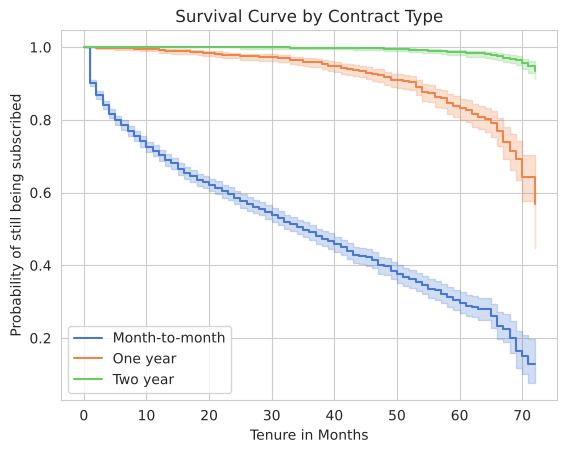

In [5]:
ax = plt.subplot(111)
for contract in ["Month-to-month", "One year", "Two year"]:
    is_contract = (df.Contract == contract)
    KaplanMeierFitter().fit(df.tenure[is_contract], df.Churn[is_contract], label = contract).plot_survival_function(ax = ax)
plt.title("Survival Curve by Contract Type")
plt.xlabel("Tenure in Months")
plt.ylabel("Probability of still being subscribed")
plt.show()

In [6]:
best_model = CoxPHFitter()
best_model.fit(df_model, duration_col = "tenure", event_col = "Churn", strata = ["Contract"])
best_model.print_summary(columns = ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"], decimals = 3)

<lifelines.CoxPHFitter: fitted with 7032 total observations, 5163 right-censored observations>
             duration col = 'tenure'
                event col = 'Churn'
                   strata = Contract
      baseline estimation = breslow
   number of observations = 7032
number of events observed = 1869
   partial log-likelihood = -13329.807
         time fit was run = 2026-10-22 14:38:46 UTC

---
                                      exp(coef) exp(coef) lower 95% exp(coef) upper 95%       p
covariate                                                                                      
gender_Male                               0.929               0.848               1.018   0.114
SeniorCitizen_Yes                         0.942               0.843               1.052   0.288
Partner_Yes                               0.609               0.547               0.678 <0.0005
Dependents_Yes                            0.937               0.819               1.072   0.342
PhoneService_Yes                          1.085               0.891               1.321   0.419
MultipleLines_Yes                         0.636               0.573               0.706 <0.0005
InternetService_Fiber optic               1.463               1.270               1.686 <0.0005
InternetService_No                        0.354               0.279               0.447 <0.0005
OnlineSecurity_Yes                        0.525               0.461               0.598 <0.0005
OnlineBackup_Yes                          0.531               0.477               0.591 <0.0005
DeviceProtection_Yes                      0.737               0.662               0.821 <0.0005
TechSupport_Yes                           0.663               0.583               0.753 <0.0005
StreamingTV_Yes                           0.961               0.864               1.069   0.464
StreamingMovies_Yes                       0.893               0.802               0.994   0.038
PaperlessBilling_Yes                      1.197               1.072               1.338   0.001
PaymentMethod_Credit card (automatic)     0.920               0.771               1.100   0.361
PaymentMethod_Electronic check            1.784               1.551               2.052 <0.0005
PaymentMethod_Mailed check                1.795               1.509               2.134 <0.0005
---
Concordance = 0.720
Partial AIC = 26695.614
log-likelihood ratio test = 876.835 on 18 df
-log2(p) of ll-ratio test = 577.566

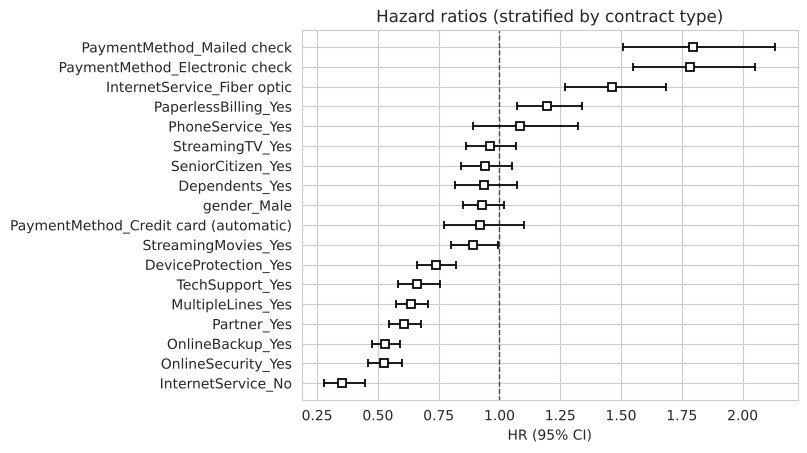

In [7]:
ax = plt.subplot(111)
best_model.plot(hazard_ratios = True, ax = ax)
plt.title("Hazard ratios (stratified by contract type)")
plt.show()

### Checking the proportional hazards assumption

In [8]:
ph_test = proportional_hazard_test(best_model, df_model, time_transform = "km")
ph_test.summary.sort_values("p").round(4)

,test_statistic,p,-log2(p)
MultipleLines_Yes,14.7995,0.0001,13.0299
StreamingTV_Yes,14.1547,0.0002,12.5360
StreamingMovies_Yes,12.2154,0.0005,11.0429
TechSupport_Yes,11.8399,0.0006,10.7523
OnlineSecurity_Yes,11.6519,0.0006,10.6065
OnlineBackup_Yes,8.7218,0.0031,8.3131
PaymentMethod_Mailed check,5.0218,0.0250,5.3202
DeviceProtection_Yes,4.8385,0.0278,5.1672
Partner_Yes,4.3546,0.0369,4.7599
PaymentMethod_Electronic check,3.9077,0.0481,4.3789


The assumption doesn't hold perfectly:

- The add-on services (`MultipleLines`, `StreamingTV`, `StreamingMovies`, `TechSupport`, `OnlineSecurity`, `OnlineBackup`) clearly violate it (p < 0.005): their effect on churn changes with tenure. They're included mainly as controls, so we keep them and read their hazard ratios as an *average* effect over time.
- Payment method, partner, and device protection are borderline (p between 0.02 and 0.05). With 7,000 customers even small deviations get flagged, so we treat these as mild.
- Internet type, paperless billing, and the demographic variables pass, and contract type is handled by stratification.

The violations are much milder than in the existing model, where three of the four variables fail (see below). They could be addressed further with time-varying effects, but as the comparison below shows, more flexible models don't predict any better.

Note: the `Concordance = 0.720` in the summary above only compares customers *within* the same contract type, so it leaves out the effect of contract type itself. The cross-validated C-index below compares all customers.

## The existing notebook's model

The existing notebook fit a Cox regression with `PaperlessBilling`, `SeniorCitizen`, `Dependents`, and `gender` (in R). Refitting it here reproduces its coefficients exactly.

In [9]:
existing_covariates = ["PaperlessBilling", "SeniorCitizen", "Dependents", "gender"]
df_existing = pd.get_dummies(df.loc[:, ["tenure", "Churn"] + existing_covariates], columns = existing_covariates, drop_first = True, dtype = float)

existing_model = CoxPHFitter()
existing_model.fit(df_existing, duration_col = "tenure", event_col = "Churn")
existing_model.print_summary(columns = ["coef", "exp(coef)", "p"], decimals = 5)

<lifelines.CoxPHFitter: fitted with 7032 total observations, 5163 right-censored observations>
             duration col = 'tenure'
                event col = 'Churn'
      baseline estimation = breslow
   number of observations = 7032
number of events observed = 1869
   partial log-likelihood = -15432.33099
         time fit was run = 2026-10-22 14:38:47 UTC

---
                         coef exp(coef)       p
covariate                                      
PaperlessBilling_Yes  0.61206   1.84423  <5e-06
SeniorCitizen_Yes     0.26499   1.30342  <5e-06
Dependents_Yes       -0.78207   0.45746  <5e-06
gender_Male          -0.02079   0.97942 0.65315
---
Concordance = 0.62804
Partial AIC = 30872.66198
log-likelihood ratio test = 441.41729 on 4 df
-log2(p) of ll-ratio test = 310.62275

In [10]:
proportional_hazard_test(existing_model, df_existing, time_transform = "km").summary.round(4)

,test_statistic,p,-log2(p)
Dependents_Yes,7.4974,0.0062,7.3385
PaperlessBilling_Yes,11.3898,0.0007,10.4032
SeniorCitizen_Yes,15.6504,0.0001,13.6799
gender_Male,2.8499,0.0914,3.4520


Three of its four variables violate the proportional hazards assumption, and it leaves out contract type, which is correlated with all of them. For example, about 71% of senior citizens are on month-to-month contracts compared to 52% of other customers, so part of the effect of contract type gets attributed to senior citizenship.

## Comparing models on unseen customers

We compare models with 5-fold cross-validation: each model is fit on 80% of the customers and evaluated on the remaining 20%, five times. Two metrics:

- **C-index** (concordance): how well the model ranks customers by churn risk. 0.5 is a coin flip, 1.0 is perfect. Here, a customer's risk is their predicted probability of having churned by 24 months.
- **Integrated Brier score (IBS)**: the average squared error of the predicted survival probabilities over months 1-60. Lower is better. A Kaplan-Meier curve with no customer variables is the baseline.

Besides the existing model and the best model, we include:
- the existing four variables stratified by contract type (the corrected version of the existing notebook);
- the same Cox model with contract type as an ordinary variable instead of strata;
- parametric (Weibull, log-normal, log-logistic) accelerated failure time models;
- a random survival forest, a flexible machine-learning model that can pick up non-linear effects and interactions.

In [11]:
df_existing_strat = pd.get_dummies(df.loc[:, ["tenure", "Churn", "Contract"] + existing_covariates], columns = existing_covariates, drop_first = True, dtype = float)
df_model_contract = pd.get_dummies(df_model, columns = ["Contract"], drop_first = True, dtype = float)

times = np.arange(1, 61)

def lifelines_model(fitter, data, strata = None):
    def fit_predict(train_idx, test_idx):
        model = fitter()
        model.fit(data.iloc[train_idx], duration_col = "tenure", event_col = "Churn", **({"strata": strata} if strata else {}))
        X_test = data.iloc[test_idx].drop(columns = ["tenure", "Churn"])
        # with strata, lifelines returns predictions grouped by stratum, so realign them to the test rows
        return model.predict_survival_function(X_test, times = times).T.loc[X_test.index].values
    return fit_predict

def random_survival_forest(data):
    def fit_predict(train_idx, test_idx):
        X_all = data.drop(columns = ["tenure", "Churn"])
        y_all = Surv.from_arrays(data.Churn.astype(bool), data.tenure)
        model = RandomSurvivalForest(n_estimators = 300, min_samples_leaf = 15, max_features = "sqrt", n_jobs = -1, random_state = 0)
        model.fit(X_all.iloc[train_idx], y_all[train_idx])
        return np.vstack([f(times) for f in model.predict_survival_function(X_all.iloc[test_idx])])
    return fit_predict

def kaplan_meier(train_idx, test_idx):
    kmf = KaplanMeierFitter().fit(df.tenure[train_idx], df.Churn[train_idx])
    return np.tile(kmf.survival_function_at_times(times).values, (len(test_idx), 1))

models = {
    "Kaplan-Meier (no variables)": kaplan_meier,
    "Existing notebook: Cox, 4 variables": lifelines_model(CoxPHFitter, df_existing),
    "Cox, 4 variables, stratified by contract": lifelines_model(CoxPHFitter, df_existing_strat, ["Contract"]),
    "Best: Cox, all variables, stratified by contract": lifelines_model(CoxPHFitter, df_model, ["Contract"]),
    "Cox, all variables, contract as a variable": lifelines_model(CoxPHFitter, df_model_contract),
    "Weibull AFT, all variables": lifelines_model(WeibullAFTFitter, df_model_contract),
    "Log-normal AFT, all variables": lifelines_model(LogNormalAFTFitter, df_model_contract),
    "Log-logistic AFT, all variables": lifelines_model(LogLogisticAFTFitter, df_model_contract),
    "Random survival forest, all variables": random_survival_forest(df_model_contract),
}

y = Surv.from_arrays(df.Churn.astype(bool), df.tenure)
folds = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 0)
scores = []
for fold, (train_idx, test_idx) in enumerate(folds.split(df, df.Churn)):
    eval_times = times[times < y[test_idx]["time"].max()]
    for name, fit_predict in models.items():
        surv = fit_predict(train_idx, test_idx)
        risk = 1 - surv[:, times == 24].ravel()
        c_index = concordance_index_censored(y[test_idx]["event"], y[test_idx]["time"], risk)[0]
        ibs = integrated_brier_score(y[train_idx], y[test_idx], surv[:, :len(eval_times)], eval_times)
        scores.append({"model": name, "fold": fold, "C-index": c_index, "IBS": ibs})

scores = pd.DataFrame(scores)
summary = scores.groupby("model", sort = False).agg(C_index = ("C-index", "mean"), C_index_sd = ("C-index", "std"), IBS = ("IBS", "mean"), IBS_sd = ("IBS", "std"))
summary.round(3)

,C_index,C_index_sd,IBS,IBS_sd
model,,,,
Kaplan-Meier (no variables),0.500,0.000,0.173,0.002
"Existing notebook: Cox, 4 variables",0.626,0.011,0.164,0.003
"Cox, 4 variables, stratified by contract",0.792,0.006,0.105,0.003
"Best: Cox, all variables, stratified by contract",0.865,0.005,0.083,0.002
"Cox, all variables, contract as a variable",0.865,0.004,0.084,0.002
"Weibull AFT, all variables",0.864,0.004,0.084,0.002
"Log-normal AFT, all variables",0.865,0.005,0.083,0.002
"Log-logistic AFT, all variables",0.865,0.005,0.083,0.002
"Random survival forest, all variables",0.859,0.004,0.093,0.001


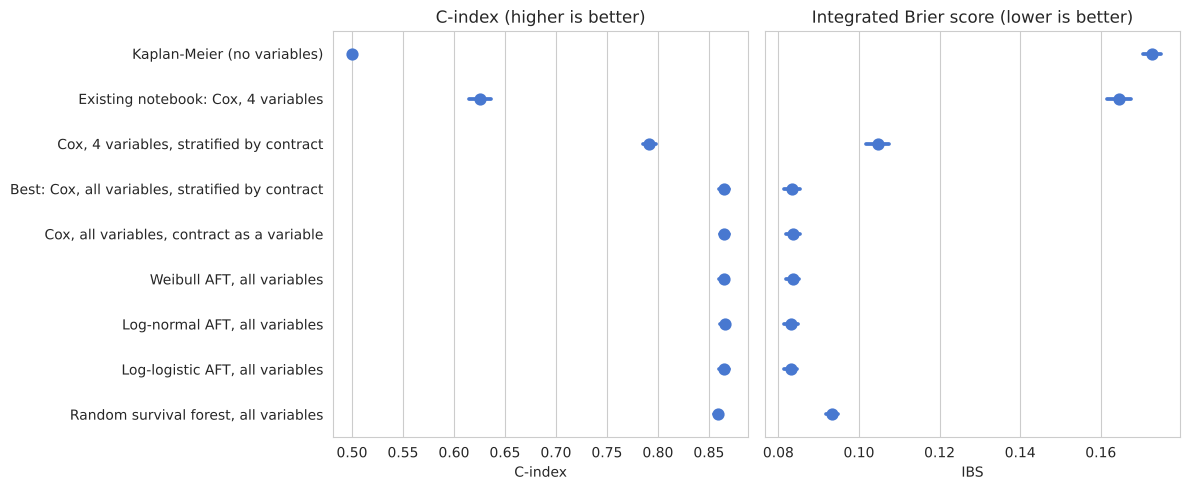

In [12]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5), sharey = True)
order = summary.index.tolist()
sns.pointplot(data = scores, y = "model", x = "C-index", order = order, linestyle = "none", errorbar = "sd", ax = axes[0])
sns.pointplot(data = scores, y = "model", x = "IBS", order = order, linestyle = "none", errorbar = "sd", ax = axes[1])
axes[0].set_title("C-index (higher is better)")
axes[1].set_title("Integrated Brier score (lower is better)")
axes[0].set_ylabel("")
plt.tight_layout()
plt.show()

### Calibration

A good model should also give *accurate* probabilities, not just a good ranking. Using the cross-validated predictions, we group customers into ten groups by their predicted probability of still being subscribed at 24 months and compare it to the observed (Kaplan-Meier) survival in each group.

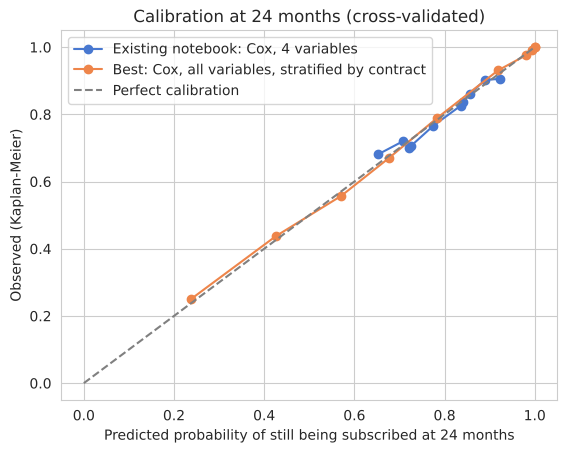

In [13]:
def calibration(fit_predict, t = 24, n_groups = 10):
    rows = []
    for train_idx, test_idx in folds.split(df, df.Churn):
        surv = fit_predict(train_idx, test_idx)
        rows.append(pd.DataFrame({"predicted": surv[:, times == t].ravel(), "tenure": df.tenure.values[test_idx], "Churn": df.Churn.values[test_idx]}))
    cv = pd.concat(rows)
    cv["group"] = pd.qcut(cv.predicted.rank(method = "first"), n_groups, labels = False)
    out = []
    for _, g in cv.groupby("group"):
        observed = KaplanMeierFitter().fit(g.tenure, g.Churn).survival_function_at_times(t).iloc[0]
        out.append({"predicted": g.predicted.mean(), "observed": observed})
    return pd.DataFrame(out)

ax = plt.subplot(111)
for name in ["Existing notebook: Cox, 4 variables", "Best: Cox, all variables, stratified by contract"]:
    cal = calibration(models[name])
    ax.plot(cal.predicted, cal.observed, marker = "o", label = name)
ax.plot([0, 1], [0, 1], linestyle = "--", color = "grey", label = "Perfect calibration")
plt.xlabel("Predicted probability of still being subscribed at 24 months")
plt.ylabel("Observed (Kaplan-Meier)")
plt.title("Calibration at 24 months (cross-validated)")
plt.legend()
plt.show()

## Why the stratified Cox model is better

- **It predicts much better on unseen customers.** Its C-index is about 0.87 versus about 0.63 for the existing model, and its integrated Brier score is about half (0.083 versus 0.164). The existing model is barely better than using no customer information at all (Kaplan-Meier, 0.173). The calibration plot shows why: both models are well calibrated, but the existing model's predicted 24-month survival only ranges from about 65% to 92%, so it can't tell customers apart. The best model's predictions range from about 24% to nearly 100%, separating customers who will almost certainly stay from those very likely to churn, while still matching what actually happened.
- **It includes the variables that matter.** Most of the improvement comes from contract type, payment method, internet type, and the add-on services, which the existing model left out. Even the existing four variables gain a lot from stratifying on contract type (C-index 0.79).
- **It handles contract type correctly.** Contract type violates the proportional hazards assumption, so the existing analysis dropped it. Stratifying keeps its information without forcing a single hazard ratio on it, and the remaining variables mostly satisfy the assumption. Three of the existing model's four variables violate it.
- **Its estimates are less confounded.** Leaving out contract type made senior citizenship look like a risk factor and inflated the effects of paperless billing and dependents.
- **More complex models don't do better.** Treating contract type as an ordinary variable and the parametric AFT models score the same within noise (±0.001), and the random survival forest is slightly worse. The effects in this data are mostly additive, so there's nothing extra for a flexible model to find. Among equally accurate models, we pick the stratified Cox model because its hazard ratios are easy to interpret and it doesn't assume a shape for contract type's survival curves. The log-logistic AFT model is a good alternative if you want to talk about predicted lifetimes ("time ratios") instead.

## What the best model tells us

Hazard ratios below 1 mean customers churn more slowly, above 1 more quickly, compared to similar customers on the same type of contract:

- **Payment method:** customers paying by electronic check or mailed check churn about **1.8 times** as fast as customers on automatic bank transfer. Automatic credit card payments are no different from bank transfer.
- **Internet service:** fiber optic customers churn about **1.5 times** as fast as DSL customers, even though (or perhaps because) they pay much more. Customers without internet service churn much more slowly.
- **Add-on services:** customers with online security, online backup, tech support, device protection, or multiple lines churn at about **0.5-0.75 times** the rate. Because the data is a snapshot, these services are recorded at the end of each customer's tenure, so long-time customers may simply have added more services. These hazard ratios are also averaged over time, since these variables don't satisfy the proportional hazards assumption.
- **Partner:** customers with a partner churn at about **0.6 times** the rate. Once partner is in the model, dependents no longer matter, since most customers with dependents also have a partner.
- **Paperless billing** has a modest effect (about **1.2 times**), much smaller than the existing notebook's 1.84.
- **Senior citizenship and gender** don't matter once everything else is accounted for.

These are associations, not causes. For example, customers who choose automatic payment may already be more committed. Moving customers to longer contracts or automatic payments are good candidates for experiments, but the data alone can't prove they would reduce churn.

### Example: predicted survival curves

The model can produce a survival curve for any customer profile. Below, two otherwise identical month-to-month fiber customers, one paying by electronic check with no add-ons, and one on automatic bank transfer with online security and tech support.

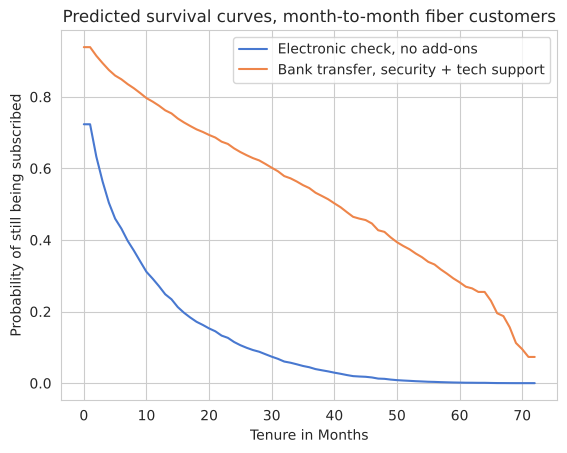

,"Electronic check, no add-ons","Bank transfer, security + tech support"
12.0,0.27,0.78
24.0,0.11,0.66
48.0,0.01,0.42


In [14]:
profile = pd.DataFrame(0.0, index = ["Electronic check, no add-ons", "Bank transfer, security + tech support"], columns = df_model.columns.drop(["tenure", "Churn"]))
profile["Contract"] = "Month-to-month"
profile["InternetService_Fiber optic"] = 1.0
profile["PhoneService_Yes"] = 1.0
profile["PaperlessBilling_Yes"] = 1.0
profile.loc["Electronic check, no add-ons", "PaymentMethod_Electronic check"] = 1.0
profile.loc["Bank transfer, security + tech support", ["OnlineSecurity_Yes", "TechSupport_Yes"]] = 1.0

predicted = best_model.predict_survival_function(profile, times = np.arange(0, 73))
predicted.columns = profile.index
predicted.plot()
plt.title("Predicted survival curves, month-to-month fiber customers")
plt.xlabel("Tenure in Months")
plt.ylabel("Probability of still being subscribed")
plt.show()
predicted.loc[[12, 24, 48]].round(2)